# rel-hm / item-sales — GNN vs LightGBM sur une cible autorégressive

> Tâche : prédire le chiffre d'affaires (`sales`) de chaque article H&M sur les 7 prochains jours.
> Dataset : RelBench `rel-hm` — 105 k articles, 1.37 M clients, 14.9 M transactions.
> Split officiel : train 2019-09-09 à 2020-08-31, val = 2020-09-07, test = 2020-09-14.

## Ce qui rend `item-sales` particulier

| Spécificité | Conséquence |
|---|---|
| Régression : comptage de ventes sur 7 j | permet de séparer « va-t-il se vendre ? » de « combien ? » (hurdle) |
| Cible ~81 % de zéros, queue longue (max ~87) | le gain relationnel peut différer entre la masse de zéros et les gros vendeurs |
| Signal dominé par l'autorégression : `sales(t) ≈ sales(t-1)` | hypothèse centrale : l'autocorrélation sature et court-circuite le signal relationnel |
| Une seule relation bipartite `customer ↔ article`, énorme (12.9 M arêtes) | un « saut » correspond au co-achat item-item, pas à un chemin multi-tables |

## Question de recherche

Quand la cible est une série temporelle de comptage fortement autocorrélée,
que reste-t-il à apprendre de la structure relationnelle ?

## Hypothèses testées

| Hyp. | Énoncé testable | Ablation |
|---|---|---|
| H1 | retirer les lags dégrade bien plus que retirer les sauts | temporelle |
| H2 | le gain 0 à 2 sauts est faible (proche d'un filtrage collaboratif item-item) | profondeur |
| H3 | le graphe aide surtout le « vend / vend pas », peu le « combien » | hurdle |

## Structure du notebook

| Section | Contenu |
|---|---|
| §1 Données | chargement RelBench, statistiques |
| §2 LightGBM | baseline table-plate (features statiques + temporelles + lags) |
| §3–§9 GNN | encodage, graphe, modèle HeteroSAGE, entraînement de référence, évaluation |
| §10 Ablations | 9 expériences, chargées depuis JSON (déjà calculées) |
| §11 Synthèse | récapitulatif en 6 points, figure 4 panneaux, conclusion |

## §0 — Imports & setup

In [1]:
import os, json, time, gc, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv

import lightgbm as lgb
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import roc_auc_score, average_precision_score
from relbench.tasks import get_task

# RelBench cherche les données en chemin relatif 'data/hm-recommendation/'
# on se place à la racine du projet (parent de notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(PROJECT_ROOT)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | device : {device}')

RESULTS_DIR = Path('reports/ablations')
load_abl = lambda f: pd.DataFrame(json.load(open(RESULTS_DIR / f)))

PyTorch 2.7.1+cu118 | device : cuda


## §1 — Chargement des données

RelBench gère le split temporel : `train` = toutes les semaines jusqu'à 2020-08-31,
`val` = 2020-09-07 (1 semaine), `test` = 2020-09-14 (labels cachés — leaderboard officiel).

In [2]:
print('Chargement rel-hm...')
task = get_task('rel-hm', 'item-sales', download=False)
db   = task.dataset.get_db()

articles_df     = db.table_dict['article'].df.copy()
customers_df    = db.table_dict['customer'].df.copy()
transactions_df = db.table_dict['transactions'].df.copy()

train_tbl = task.get_table('train')
val_tbl   = task.get_table('val')
test_tbl  = task.get_table('test')

VAL_TIMESTAMP  = val_tbl.df['timestamp'].iloc[0]
TEST_TIMESTAMP = test_tbl.df['timestamp'].iloc[0]

df_train = train_tbl.df.copy()
df_val   = val_tbl.df.copy()
df_test  = test_tbl.df.copy()

print(f'Articles     : {len(articles_df):,}')
print(f'Customers    : {len(customers_df):,}')
print(f'Transactions : {len(transactions_df):,}')
print(f'Val  : {VAL_TIMESTAMP.date()} | Test : {TEST_TIMESTAMP.date()}')
print(f'Train: {len(df_train):,} lignes  {df_train["timestamp"].min().date()} → {df_train["timestamp"].max().date()}')
print(f'Val  : {len(df_val):,} lignes')
print(f'% zéros train : {(df_train["sales"]==0).mean()*100:.1f}%  '
      f'| max ventes : {df_train["sales"].max()}')

Chargement rel-hm...
Loading Database object from /home/infres/sryszfeld-24/.cache/relbench/rel-hm/db...


Done in 2.36 seconds.


Articles     : 105,542
Customers    : 1,371,980
Transactions : 15,187,287
Val  : 2020-09-07 | Test : 2020-09-14
Train: 5,488,184 lignes  2019-09-09 → 2020-08-31
Val  : 105,542 lignes
% zéros train : 81.4%  | max ventes : 87.16259322033835


## §2 — Baseline LightGBM (table plate)

Approche table-plate classique : features statiques (attributs article),
features temporelles (semaine, mois) et lags (ventes de la semaine précédente).
Le modèle est entraîné sur toute la période train sauf la dernière semaine (early stopping).

In [3]:
# Features statiques — attributs article
CAT_COLS = [
    'product_type_name', 'product_group_name', 'graphical_appearance_name',
    'colour_group_name', 'department_name', 'index_name',
    'section_name', 'garment_group_name',
]
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
articles_enc = articles_df[['article_id'] + CAT_COLS].copy()
articles_enc[CAT_COLS] = enc.fit_transform(articles_enc[CAT_COLS].astype(str)).astype('int32')

def add_article_features(df):
    return df.merge(articles_enc, on='article_id', how='left')

# Features temporelles
def add_time_features(df):
    df = df.copy()
    df['week_of_year'] = df['timestamp'].dt.isocalendar().week.astype('int32')
    df['month']        = df['timestamp'].dt.month.astype('int32')
    df['year']         = df['timestamp'].dt.year.astype('int32')
    return df

df_train = add_article_features(add_time_features(df_train))
df_val   = add_article_features(add_time_features(df_val))
df_test  = add_article_features(add_time_features(df_test))

# Lag features (signal autorégressif)
df_train = df_train.sort_values(['article_id', 'timestamp'])
df_train['lag1'] = df_train.groupby('article_id')['sales'].shift(1)
df_train['lag2'] = df_train.groupby('article_id')['sales'].shift(2)
df_train['lag4'] = df_train.groupby('article_id')['sales'].shift(4)
df_train['ma4']  = df_train.groupby('article_id')['sales'].transform(
    lambda x: x.shift(1).rolling(4, min_periods=1).mean())

# Val : lags = dernière semaine du train par article
last_row = (df_train.sort_values(['article_id', 'timestamp'])
            .groupby('article_id', as_index=False)[['sales', 'lag1', 'lag2', 'ma4']]
            .last()
            .rename(columns={'sales':'lag1','lag1':'lag2','lag2':'lag4','ma4':'ma4'}))
df_val  = df_val.merge(last_row[['article_id','lag1','lag2','lag4','ma4']], on='article_id', how='left')

# Test : lags = ventes val
test_lag = (df_val[['article_id','sales','lag1','lag2','ma4']]
            .rename(columns={'sales':'lag1','lag1':'lag2','lag2':'lag4','ma4':'ma4'}))
df_test = df_test.merge(test_lag[['article_id','lag1','lag2','lag4','ma4']], on='article_id', how='left')

print('Features construites :', CAT_COLS + ['week_of_year','month','year','lag1','lag2','lag4','ma4'])

Features construites : ['product_type_name', 'product_group_name', 'graphical_appearance_name', 'colour_group_name', 'department_name', 'index_name', 'section_name', 'garment_group_name', 'week_of_year', 'month', 'year', 'lag1', 'lag2', 'lag4', 'ma4']


In [4]:
FEATURES = CAT_COLS + ['week_of_year', 'month', 'year', 'lag1', 'lag2', 'lag4', 'ma4']
TARGET   = 'sales'

# Dernière semaine train = inner_val (early stopping) ; ne sert pas à l'éval finale
LAST_TRAIN_TS = df_train['timestamp'].max()
inner_train = df_train[df_train['timestamp'] < LAST_TRAIN_TS]
inner_val   = df_train[df_train['timestamp'] == LAST_TRAIN_TS]

X_inner_train, y_inner_train = inner_train[FEATURES], inner_train[TARGET]
X_inner_val,   y_inner_val   = inner_val[FEATURES],   inner_val[TARGET]
X_eval,        y_eval        = df_val[FEATURES],       df_val[TARGET]

lgbm = lgb.LGBMRegressor(
    n_estimators=1000, learning_rate=0.05, num_leaves=63,
    min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
    random_state=42, verbosity=-1,
)
lgbm.fit(
    X_inner_train, y_inner_train,
    categorical_feature=CAT_COLS,
    eval_set=[(X_inner_val, y_inner_val)],
    callbacks=[lgb.early_stopping(50, verbose=True)],
)
print(f'Modèle entraîné — {lgbm.best_iteration_} arbres')

Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[74]	valid_0's l2: 0.098058
Modèle entraîné — 74 arbres


Évaluation sur val officiel RelBench (2020-09-07)
Métrique       LightGBM   Persistance (lag1)
----------------------------------------------
MAE              0.0501               0.0472
RMSE             0.4089               0.4323
R²               0.6188               0.5739


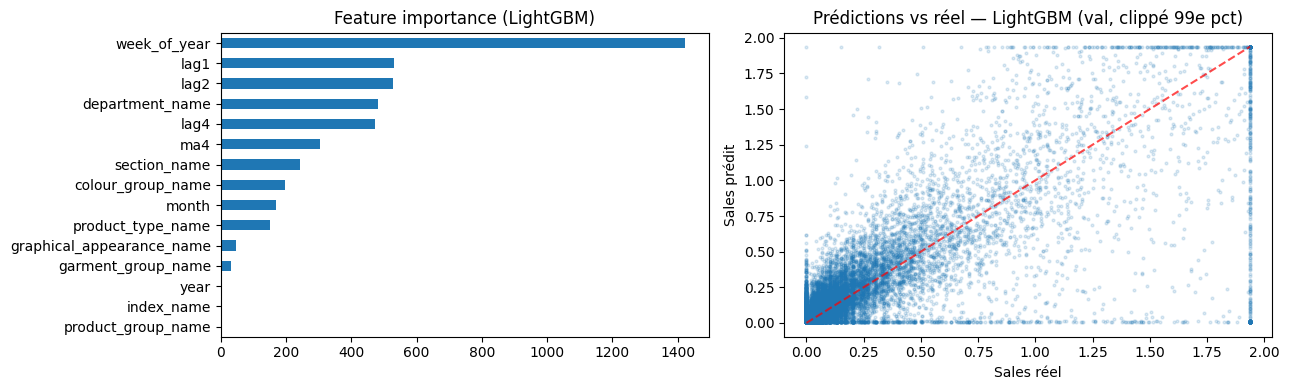

In [5]:
y_pred_lgbm = lgbm.predict(X_eval)
y_true_lgbm = y_eval.values

mae_lgbm  = mean_absolute_error(y_true_lgbm, y_pred_lgbm)
rmse_lgbm = np.sqrt(mean_squared_error(y_true_lgbm, y_pred_lgbm))
r2_lgbm   = r2_score(y_true_lgbm, y_pred_lgbm)

# Baseline persistance : prédire lag1
lag1_arr  = X_eval['lag1'].fillna(0).values
mae_p     = mean_absolute_error(y_true_lgbm, lag1_arr)
rmse_p    = np.sqrt(mean_squared_error(y_true_lgbm, lag1_arr))
r2_p      = r2_score(y_true_lgbm, lag1_arr)

print('Évaluation sur val officiel RelBench (2020-09-07)')
print(f'{"Métrique":<10} {"LightGBM":>12} {"Persistance (lag1)":>20}')
print('-' * 46)
print(f'{"MAE":<10} {mae_lgbm:>12.4f} {mae_p:>20.4f}')
print(f'{"RMSE":<10} {rmse_lgbm:>12.4f} {rmse_p:>20.4f}')
print(f'{"R²":<10} {r2_lgbm:>12.4f} {r2_p:>20.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
imp = pd.Series(lgbm.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind='barh', ax=axes[0], title='Feature importance (LightGBM)')
clip = np.percentile(y_true_lgbm, 99)
axes[1].scatter(np.clip(y_true_lgbm,0,clip), np.clip(y_pred_lgbm,0,clip), alpha=0.15, s=4)
axes[1].plot([0,clip],[0,clip],'r--', alpha=0.7)
axes[1].set_xlabel('Sales réel'); axes[1].set_ylabel('Sales prédit')
axes[1].set_title('Prédictions vs réel — LightGBM (val, clippé 99e pct)')
plt.tight_layout(); plt.show()

# Stocker pour la comparaison finale
REF = {'LightGBM': dict(mae=mae_lgbm, rmse=rmse_lgbm, r2=r2_lgbm),
       'Persistance (lag1)': dict(mae=mae_p, rmse=rmse_p, r2=r2_p)}

LightGBM bat la persistance sur RMSE et R² (il est meilleur sur les gros vendeurs),
mais la persistance gagne en MAE : sur la masse des 81 % de zéros, recopier la semaine
précédente est difficile à battre. Résultat classique d'une cible très déséquilibrée.

## §3 — Encodage des nœuds (GNN)

Articles (105 k nœuds) : 5 features catégorielles et 4 features historiques de ventes
(lag1, moyenne 4 dernières semaines, moyenne historique, max historique) en `log1p`, standardisées.
Les features historiques sont calculées strictement sur le train (< val), donc sans fuite.

Clients (1.37 M nœuds) : club_member_status, fashion_news_frequency et âge.

`OrdinalEncoder` réémet `np.nan` pour les valeurs manquantes : on applique donc
`fillna('missing')` avant l'encodage. Sinon les NaN se propagent dans le message passing
et la loss devient NaN (RMSE infini).

In [6]:
# Articles (105k nœuds)
ART_CAT = ['product_type_name', 'product_group_name', 'colour_group_name',
           'department_name', 'garment_group_name']

enc_art    = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
art_cat_enc = enc_art.fit_transform(
    articles_df[ART_CAT].fillna('missing').astype(str)).astype(np.float32)
art_cat_enc = (art_cat_enc - art_cat_enc.mean(0)) / (art_cat_enc.std(0) + 1e-8)

art_map = {aid: i for i, aid in enumerate(articles_df['article_id'].values)}
N_ART   = len(art_map)

# Features historiques par article (signal autorégressif pour le GNN)
_panel = train_tbl.df
_weeks = np.sort(_panel['timestamp'].unique())
_lag1  = _panel[_panel['timestamp'] == _weeks[-1]].set_index('article_id')['sales']
_rec4  = _panel[_panel['timestamp'].isin(_weeks[-4:])].groupby('article_id')['sales'].mean()
_hmean = _panel.groupby('article_id')['sales'].mean()
_hmax  = _panel.groupby('article_id')['sales'].max()

art_hist = np.zeros((N_ART, 4), dtype=np.float32)
for j, s in enumerate([_lag1, _rec4, _hmean, _hmax]):
    idx = np.fromiter((art_map[a] for a in s.index), dtype=np.int64, count=len(s))
    art_hist[idx, j] = np.log1p(s.values.astype(np.float32))
art_hist = (art_hist - art_hist.mean(0)) / (art_hist.std(0) + 1e-8)

# Deux variantes : complètes (catég. + hist) et sans historique (pour ablation H1)
art_feat        = torch.tensor(np.hstack([art_cat_enc, art_hist]), dtype=torch.float32)  # [N_art, 9]
art_feat_nohist = torch.tensor(art_cat_enc, dtype=torch.float32)                          # [N_art, 5]
assert torch.isfinite(art_feat).all() and torch.isfinite(art_feat_nohist).all(), 'NaN dans art_feat'

# Clients (1.37M nœuds)
CUST_CAT  = ['club_member_status', 'fashion_news_frequency']
enc_cust   = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
cust_cat_enc = enc_cust.fit_transform(
    customers_df[CUST_CAT].fillna('missing').astype(str)).astype(np.float32)
cust_cat_enc = (cust_cat_enc - cust_cat_enc.mean(0)) / (cust_cat_enc.std(0) + 1e-8)
cust_age  = customers_df['age'].fillna(customers_df['age'].median()).values.reshape(-1,1).astype(np.float32)
cust_age  = (cust_age - cust_age.mean()) / (cust_age.std() + 1e-8)
cust_feat = torch.tensor(np.hstack([cust_cat_enc, cust_age]), dtype=torch.float32)  # [N_cust, 3]
assert torch.isfinite(cust_feat).all(), 'NaN dans cust_feat'

cust_map = {cid: i for i, cid in enumerate(customers_df['customer_id'].values)}
N_CUST   = len(cust_map)

print(f'Article features  : {tuple(art_feat.shape)} (5 catég. + 4 hist)')
print(f'Customer features : {tuple(cust_feat.shape)} (2 catég. + âge)')

Article features  : (105542, 9) (5 catég. + 4 hist)
Customer features : (1371980, 3) (2 catég. + âge)


## §4 — Construction du graphe

Arêtes : transactions train uniquement (< val, pas de fuite). 12.86 M arêtes uniques
(customer, article), mais le full-batch sur le P100 16 GB sature si on les garde toutes
(~26 GB). On sparsifie donc en plafonnant à `K = 30` acheteurs par article, ce qui ramène
à ~1.31 M arêtes (~2.7 GB) tout en gardant chaque article couvert.

In [7]:
tx_train = transactions_df[transactions_df['t_dat'] < VAL_TIMESTAMP].copy()

edges_full = (tx_train.groupby(['customer_id','article_id'])
              .size().reset_index(name='n_tx'))
edges_full['c_idx'] = edges_full['customer_id'].map(cust_map)
edges_full['a_idx'] = edges_full['article_id'].map(art_map)
edges_full = edges_full.dropna(subset=['c_idx','a_idx'])
edges_full['c_idx'] = edges_full['c_idx'].astype(int)
edges_full['a_idx'] = edges_full['a_idx'].astype(int)
edges_full = edges_full[['c_idx','a_idx']].reset_index(drop=True)

DEFAULT_K = 30

def build_graph(max_cust_per_art=DEFAULT_K, seed=0, art_x=None):
    """Graphe bipartite customer↔article, sparsifié à K acheteurs/article."""
    if art_x is None: art_x = art_feat
    e = edges_full.sample(frac=1.0, random_state=seed)
    e = e.assign(_rank=e.groupby('a_idx').cumcount())
    e = e[e['_rank'] < max_cust_per_art]
    c_src = torch.tensor(e['c_idx'].values, dtype=torch.long)
    a_dst = torch.tensor(e['a_idx'].values, dtype=torch.long)
    g = HeteroData()
    g['article'].x  = art_x
    g['customer'].x = cust_feat
    g['customer','buys',    'article'].edge_index = torch.stack([c_src, a_dst])
    g['article', 'rev_buys','customer'].edge_index = torch.stack([a_dst, c_src])
    return g, len(e)

_g, _ne = build_graph()
print(f'Graphe défaut (K={DEFAULT_K}, seed=0) : {_ne:,} arêtes')
print(f'Articles couverts : {edges_full["a_idx"].nunique():,} / {N_ART:,}')
del _g

Graphe défaut (K=30, seed=0) : 1,310,548 arêtes
Articles couverts : 70,131 / 105,542


## §5 — Préparation des tenseurs cibles

Pour chaque ligne (article, semaine), on calcule les lags bruts des semaines précédentes.
Bruts (pas de log1p), ils gardent une relation linéaire avec la cible, ce qui permet à la tête
de retrouver la persistance puis de l'améliorer. C'est le setup qui fait gagner LightGBM, qu'on
reproduit ici.

In [8]:
_pan  = train_tbl.df[['article_id','timestamp','sales']].copy()
_wk   = np.sort(_pan['timestamp'].unique())
_n_wk = len(_wk)
_wkmap = {w: i for i, w in enumerate(_wk)}
_wkmap[VAL_TIMESTAMP]  = _n_wk
_wkmap[TEST_TIMESTAMP] = _n_wk + 1

_sales_mat = (_pan.assign(w=_pan['timestamp'].map(_wkmap))
              .pivot_table(index='article_id', columns='w', values='sales',
                           aggfunc='sum', fill_value=0.0)
              .reindex(index=articles_df['article_id'].values, fill_value=0.0)
              .reindex(columns=range(_n_wk), fill_value=0.0)
              .values.astype(np.float32))
_artrow = {a: i for i, a in enumerate(articles_df['article_id'].values)}
_PAD = 4
_padmat = np.concatenate([
    np.zeros((_sales_mat.shape[0], _PAD), np.float32),
    _sales_mat,
    np.zeros((_sales_mat.shape[0], 2), np.float32)], axis=1)

def _lag_feats(article_ids, week_idx):
    r = pd.Series(article_ids).map(_artrow).fillna(-1).astype(int).values
    w = np.asarray(week_idx, dtype=int)
    rr, c = np.where(r>=0, r, 0), _PAD + w
    lag1 = _padmat[rr, c-1]
    lag2 = _padmat[rr, c-2]
    ma4  = (_padmat[rr,c-1]+_padmat[rr,c-2]+_padmat[rr,c-3]+_padmat[rr,c-4]) / 4.0
    out  = np.stack([lag1, lag2, ma4], axis=1)
    out[r<0] = 0.0
    return out.astype(np.float32)

def prepare(df_task, temporal_scaler=None, fit_scaler=False):
    df = df_task.copy()
    df['a_idx'] = df['article_id'].map(art_map)
    df = df.dropna(subset=['a_idx']); df['a_idx'] = df['a_idx'].astype(int)
    w_idx = df['timestamp'].map(_wkmap).astype(int).values
    time_raw = np.column_stack([
        df['timestamp'].dt.isocalendar().week.astype(float).values,
        df['timestamp'].dt.month.values.astype(float),
        _lag_feats(df['article_id'].values, w_idx),
    ]).astype(np.float32)
    if fit_scaler:
        temporal_scaler = StandardScaler()
        time_norm = temporal_scaler.fit_transform(time_raw)
    else:
        time_norm = temporal_scaler.transform(time_raw)
    ai = torch.tensor(df['a_idx'].values, dtype=torch.long)
    tf = torch.tensor(time_norm, dtype=torch.float32)
    yt = torch.tensor(df['sales'].values, dtype=torch.float32) if 'sales' in df.columns else None
    return ai, tf, yt, temporal_scaler, df

ai_train, tf_train, y_train, scaler_t, df_tr = prepare(train_tbl.df, fit_scaler=True)
ai_val,   tf_val,   y_val,   _,        df_vl = prepare(val_tbl.df,   scaler_t)
ai_test,  tf_test,  y_test,  _,        df_ts = prepare(test_tbl.df,  scaler_t)

print(f'Tenseurs train : ai={tuple(ai_train.shape)}  tf={tuple(tf_train.shape)}  y={tuple(y_train.shape)}')
print(f'Tenseurs val   : ai={tuple(ai_val.shape)}    tf={tuple(tf_val.shape)}    y={tuple(y_val.shape)}')
print('Features temporelles : semaine, mois, lag1, lag2, ma4 (bruts + standardisés)')

Tenseurs train : ai=(5488184,)  tf=(5488184, 5)  y=(5488184,)
Tenseurs val   : ai=(105542,)    tf=(105542, 5)    y=(105542,)
Features temporelles : semaine, mois, lag1, lag2, ma4 (bruts + standardisés)


## §6 — Modèle HeteroGraphSAGE

Architecture :
- Projections linéaires vers l'espace `hidden` pour articles et clients
- `n_layers` convolutions HeteroSAGE (0 = aucun message passing)
- Skip connection : les features article brutes sont réinjectées dans la tête. Sans elle,
  l'agrégation `mean` lisse le `lag1` qui porte le signal et le modèle collapse.
- Tête MLP : embedding lissé, features brutes (skip) et features temporelles par ligne

Le paramètre `n_layers` est le levier central des ablations H2 :
0 saut = aucune structure, 1 = acheteurs directs, 2 = co-achat item-item.

In [9]:
class HeteroSAGE(nn.Module):
    def __init__(self, in_art, in_cust, emb_dim=32, hidden=64, n_temporal=5,
                 n_layers=2, aggr='mean'):
        super().__init__()
        self.in_art, self.n_layers = in_art, n_layers
        self.art_emb  = nn.Embedding(N_ART,  emb_dim)
        self.cust_emb = nn.Embedding(N_CUST, emb_dim // 2)
        nn.init.normal_(self.art_emb.weight,  std=0.01)
        nn.init.normal_(self.cust_emb.weight, std=0.01)
        self.proj = nn.ModuleDict({
            'article' : nn.Linear(in_art  + emb_dim,      hidden),
            'customer': nn.Linear(in_cust + emb_dim // 2, hidden),
        })
        self.convs = nn.ModuleList([
            HeteroConv({
                ('customer','buys',    'article') : SAGEConv(hidden, hidden, aggr=aggr),
                ('article', 'rev_buys','customer'): SAGEConv(hidden, hidden, aggr=aggr),
            }, aggr='sum')
            for _ in range(n_layers)
        ])
        self.head = nn.Sequential(
            nn.Linear(hidden + in_art + n_temporal, hidden),
            nn.ReLU(), nn.Dropout(0.1), nn.Linear(hidden, 1),
        )

    def encode(self, x_dict, edge_index_dict):
        art_ids  = torch.arange(N_ART,  device=x_dict['article'].device)
        cust_ids = torch.arange(N_CUST, device=x_dict['customer'].device)
        h = {
            'article' : F.relu(self.proj['article'](torch.cat([x_dict['article'],  self.art_emb(art_ids)],  1))),
            'customer': F.relu(self.proj['customer'](torch.cat([x_dict['customer'], self.cust_emb(cust_ids)],1))),
        }
        for conv in self.convs:
            h = {k: F.relu(v) for k, v in conv(h, edge_index_dict).items()}
        return h

    def forward(self, x_dict, edge_index_dict, art_idx, time_feats):
        h   = self.encode(x_dict, edge_index_dict)
        emb = h['article'][art_idx]
        raw = x_dict['article'][art_idx]   # skip : lag1 & co. en chemin direct
        return self.head(torch.cat([emb, raw, time_feats], dim=1)).squeeze(1)

## §7 — Harness d'ablation

Fonction unique `train_and_eval(...)` : entraîne un HeteroSAGE et renvoie ses métriques.
Toutes les expériences passent par elle, ce qui garde les comparaisons à modèle fixe ; seul
l'argument ciblé varie.

| Argument | Hypothèse | Effet |
|---|---|---|
| `n_layers` ∈ {0,1,2} | H2 | quantité de structure (0 = aucune) |
| `use_temporal` | H1 | active ou coupe les lags par ligne |
| `use_art_hist` | H1 | active ou coupe l'historique agrégé par article |
| `seed` | reproductibilité | init modèle et tirage des acheteurs |
| `max_cust_per_art` | densité | acheteurs gardés par article |
| `aggr` | agrégateur | mean / sum / max (SAGEConv) |

In [10]:
RESULTS_DIR = Path('reports/ablations'); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True, seed=0,
                   max_cust_per_art=DEFAULT_K, aggr='mean',
                   epochs=200, patience=20, lr=5e-4, wd=0.0,
                   emb_dim=32, hidden=64, return_model=False, verbose=False):
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    set_seed(seed)
    t0 = time.time()

    art_x  = art_feat if use_art_hist else art_feat_nohist
    in_art = art_x.shape[1]
    g, n_edges = build_graph(max_cust_per_art, seed, art_x)
    g = g.to(device)
    x_dict, edge_index_dict = g.x_dict, g.edge_index_dict

    tf_tr = tf_train if use_temporal else tf_train[:, :0]
    tf_vl = tf_val   if use_temporal else tf_val[:, :0]
    n_temporal = tf_tr.shape[1]

    model = HeteroSAGE(in_art=in_art, in_cust=cust_feat.shape[1],
                       emb_dim=emb_dim, hidden=hidden,
                       n_temporal=n_temporal, n_layers=n_layers, aggr=aggr).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    ai_tr_d = ai_train.to(device); tf_tr_d = tf_tr.to(device)
    ai_vl_d = ai_val.to(device);   tf_vl_d = tf_vl.to(device)
    y_tr_d  = y_train.clamp(min=0).to(device)
    y_vl_d  = y_val.clamp(min=0).to(device)

    best_rmse, ctr, epoch = float('inf'), 0, 0
    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        pred = model(x_dict, edge_index_dict, ai_tr_d, tf_tr_d)
        loss = F.mse_loss(pred, y_tr_d)
        if not torch.isfinite(loss):
            break
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        opt.step()
        model.eval()
        with torch.no_grad():
            vp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0)
            vr = torch.sqrt(F.mse_loss(vp, y_vl_d)).item()
        if np.isfinite(vr) and vr < best_rmse:
            best_rmse, ctr = vr, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            ctr += 1
        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(f'  epoch {epoch:3d} | loss {loss.item():.4f} | Val RMSE {vr:.4f}')
        if ctr >= patience: break

    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        yp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0).cpu().numpy()
    yt = y_val.numpy()
    res = {
        'n_layers': n_layers, 'use_temporal': use_temporal, 'use_art_hist': use_art_hist,
        'aggr': aggr, 'seed': seed, 'max_cust_per_art': max_cust_per_art, 'n_edges': int(n_edges),
        'mae':  float(mean_absolute_error(yt, yp)),
        'rmse': float(np.sqrt(mean_squared_error(yt, yp))),
        'r2':   float(r2_score(yt, yp)),
        'std_pred': float(yp.std()), 'std_true': float(yt.std()),
        'corr': float(np.corrcoef(yp, yt)[0, 1]),
        'best_val_rmse': float(best_rmse), 'epochs_ran': int(epoch),
        'sec': round(time.time() - t0, 1),
    }
    if return_model: res['_model'], res['_y_pred_val'] = model, yp
    else: del model
    del g, x_dict, edge_index_dict
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return res

print('Harness prêt : train_and_eval(n_layers, use_temporal, use_art_hist, seed, aggr, ...)')

Harness prêt : train_and_eval(n_layers, use_temporal, use_art_hist, seed, aggr, ...)


## §8 — Entraînement de référence (2 sauts, features complètes)

Un seul run (seed=0) pour exposer le modèle et les prédictions.
Les comparaisons statistiques (± std) sont dans les ablations (§10).

In [11]:
baseline = train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True,
                          seed=0, epochs=200, patience=20,
                          return_model=True, verbose=True)

model      = baseline['_model']
y_pred_gnn = baseline['_y_pred_val']

print(f'\nBaseline GNN (2 sauts, seed=0) |'
      f' RMSE {baseline["rmse"]:.4f} | MAE {baseline["mae"]:.4f} |'
      f' R² {baseline["r2"]:.4f} | corr {baseline["corr"]:.3f}'
      f' | {baseline["epochs_ran"]} epochs | {baseline["sec"]}s')

  epoch   1 | loss 0.2549 | Val RMSE 0.6511


  epoch  20 | loss 0.1804 | Val RMSE 0.5659


  epoch  40 | loss 0.1309 | Val RMSE 0.5161


  epoch  60 | loss 0.1114 | Val RMSE 0.4699


  epoch  80 | loss 0.1039 | Val RMSE 0.4600


...

  epoch 140 | loss 0.0945 | Val RMSE 0.4442


  epoch 160 | loss 0.0922 | Val RMSE 0.4421


  epoch 180 | loss 0.0903 | Val RMSE 0.4411


  epoch 200 | loss 0.0892 | Val RMSE 0.4405



Baseline GNN (2 sauts, seed=0) | RMSE 0.4403 | MAE 0.0599 | R² 0.5580 | corr 0.748 | 200 epochs | 107.6s


## §9 — Évaluation & comparaison des trois approches

In [12]:
y_true_np = y_val.numpy()
y_pred_gnn = np.clip(y_pred_gnn, 0, None)

mae_gnn  = mean_absolute_error(y_true_np, y_pred_gnn)
rmse_gnn = np.sqrt(mean_squared_error(y_true_np, y_pred_gnn))
r2_gnn   = r2_score(y_true_np, y_pred_gnn)

last_train_ts = train_tbl.df['timestamp'].max()
last_week     = train_tbl.df[train_tbl.df['timestamp'] == last_train_ts]
lag1_per_art  = last_week.set_index('article_id')['sales']
lag1_arr_gnn  = df_vl['article_id'].map(lag1_per_art).fillna(0).values
mae_p2  = mean_absolute_error(y_true_np, lag1_arr_gnn)
rmse_p2 = np.sqrt(mean_squared_error(y_true_np, lag1_arr_gnn))
r2_p2   = r2_score(y_true_np, lag1_arr_gnn)

print(f'Évaluation sur val officiel RelBench ({VAL_TIMESTAMP.date()})')
print(f'{"Métrique":<10} {"HeteroSAGE":>14} {"LightGBM":>12} {"Persistance":>14}')
print('-' * 55)
for m, g, l, p in [('MAE', mae_gnn, mae_lgbm, mae_p2),
                    ('RMSE',rmse_gnn,rmse_lgbm,rmse_p2),
                    ('R²',  r2_gnn,  r2_lgbm,  r2_p2)]:
    print(f'{m:<10} {g:>14.4f} {l:>12.4f} {p:>14.4f}')

Évaluation sur val officiel RelBench (2020-09-07)
Métrique       HeteroSAGE     LightGBM    Persistance
-------------------------------------------------------
MAE                0.0599       0.0501         0.0472
RMSE               0.4403       0.4089         0.4323
R²                 0.5580       0.6188         0.5739


=== Diagnostic collapse ===
std(y_true)      : 0.6623
std(y_pred GNN)  : 0.4684  (si très petit : collapse)
corr(pred, true) : 0.7481  (proche de 0 : aucun lien)


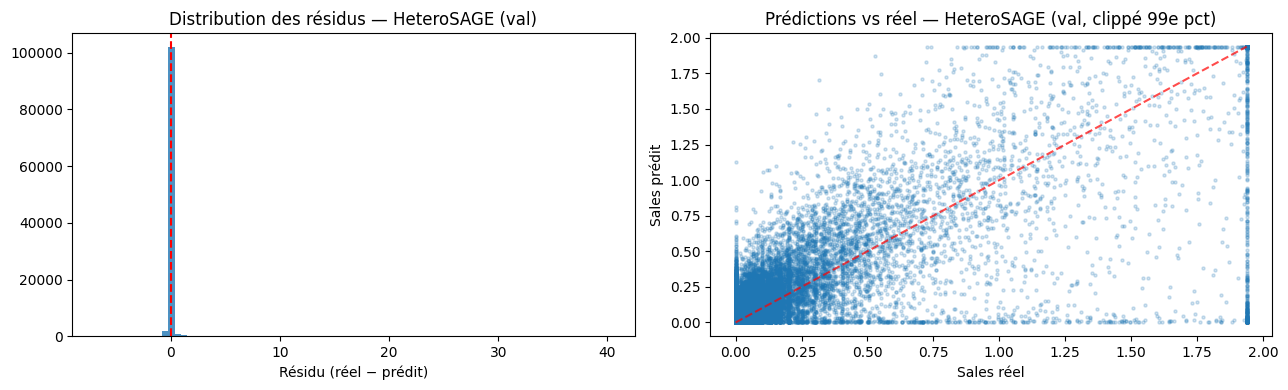

In [13]:
# Diagnostic : le modèle a-t-il appris, ou prédit-il ~une constante ?
print('=== Diagnostic collapse ===')
print(f'std(y_true)      : {y_true_np.std():.4f}')
print(f'std(y_pred GNN)  : {y_pred_gnn.std():.4f}  (si très petit : collapse)')
print(f'corr(pred, true) : {np.corrcoef(y_pred_gnn, y_true_np)[0,1]:.4f}  (proche de 0 : aucun lien)')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
residuals = y_true_np - y_pred_gnn
axes[0].hist(residuals, bins=80, alpha=0.8, edgecolor='none')
axes[0].axvline(0, color='red', lw=1.5, ls='--')
axes[0].set_title('Distribution des résidus — HeteroSAGE (val)')
axes[0].set_xlabel('Résidu (réel − prédit)')
clip = np.percentile(y_true_np, 99)
axes[1].scatter(np.clip(y_true_np,0,clip), np.clip(y_pred_gnn,0,clip), alpha=0.2, s=5)
axes[1].plot([0,clip],[0,clip],'r--', alpha=0.7)
axes[1].set_xlabel('Sales réel'); axes[1].set_ylabel('Sales prédit')
axes[1].set_title('Prédictions vs réel — HeteroSAGE (val, clippé 99e pct)')
plt.tight_layout(); plt.show()

## §10 — Ablations

Toutes les ablations ont déjà été calculées (GPU, ~100 s/run).
Les cellules ci-dessous chargent les résultats depuis `reports/ablations/` et les affichent.
Le code d'entraînement correspondant est dans §7 (`train_and_eval`).

Vue d'ensemble des 9 expériences :

| # | Hypothèse | Variable | Fichier JSON |
|---|---|---|---|
| 10.1 | H2 — Profondeur | `n_layers` ∈ {0,1,2}, features complètes | `depth_ablation.json` |
| 10.2 | H1 — Autorégression | `use_temporal` × `use_art_hist`, 2 sauts | `temporal_ablation.json` |
| 10.3 | H2bis — Structure seule | `n_layers` ∈ {0,1,2}, sans autorégression | `structure_only_ablation.json` |
| 10.4 | H3 — Hurdle | AUROC(vend?) / R²(combien?) vs profondeur | `hurdle_depth.json` |
| 10.5 | H2ter — Densité | K = 30 vs 100 acheteurs/article | `density_ablation.json` |
| 10.6 | H2quater — Agrégateur | mean / sum / max | `aggregator_ablation.json` |
| 10.7 | Hop decay | poids du 2e saut ∈ {1.0, 0.8, 0.5, 0.2} | `hop_decay_ablation.json` |
| 10.8 | Feature ablation | catégorielles article vs lags seuls | `feature_ablation.json` |
| 10.9 | Features enrichies | features comportementales (articles + clients) | `rich_features_ablation.json` |

### §10.1 — H2 : Profondeur (0 / 1 / 2 sauts)

La structure de co-achat (article, clients, autres articles) apporte-t-elle quelque chose
au-delà de l'historique propre de l'article ? 3 seeds × 3 profondeurs = 9 runs (features complètes).

In [14]:
depth = load_abl('depth_ablation.json')
agg_d = depth.groupby('n_layers')[['rmse','mae','r2','corr']].agg(['mean','std'])

print('=== H2 — Profondeur (mean ± std, 3 seeds) ===')
for nl in [0, 1, 2]:
    r, rs = agg_d[('r2','mean')][nl], agg_d[('r2','std')][nl]
    m, ms = agg_d[('rmse','mean')][nl], agg_d[('rmse','std')][nl]
    print(f'  {nl} saut(s) : RMSE {m:.4f} ± {ms:.4f}  |  R² {r:.4f} ± {rs:.4f}')
delta = agg_d[('r2','mean')][2] - agg_d[('r2','mean')][0]
print(f'\nΔ R² (0 → 2 sauts) = {delta:+.4f}',
      'la structure nuit légèrement en présence des lags' if delta < 0 else 'gain marginal')

=== H2 — Profondeur (mean ± std, 3 seeds) ===
  0 saut(s) : RMSE 0.4320 ± 0.0015  |  R² 0.5745 ± 0.0030
  1 saut(s) : RMSE 0.4379 ± 0.0007  |  R² 0.5628 ± 0.0014
  2 saut(s) : RMSE 0.4377 ± 0.0024  |  R² 0.5633 ± 0.0047

Δ R² (0 → 2 sauts) = -0.0112 la structure nuit légèrement en présence des lags


### §10.2 — H1 : Ablation de l'autorégression

À profondeur fixe (2 sauts), on retire successivement les sources d'autorégression :
- `use_temporal=False` : pas de lags par ligne (lag1, lag2, ma4)
- `use_art_hist=False` : pas d'historique agrégé par article (lag1, rec4, hmean, hmax)

Si la performance s'effondre ici bien plus que via la profondeur, H1 est confirmée.

In [15]:
temporal = load_abl('temporal_ablation.json')
gt = temporal.groupby(['use_temporal','use_art_hist'])['r2'].agg(['mean','std'])

configs = [(True,True,'complet'),(True,False,'sans hist. article'),
           (False,True,'sans lags/ligne'),(False,False,'sans autorégression')]
print('=== H1 — Autorégression (2 sauts, mean ± std, 3 seeds) ===')
for ut, uh, label in configs:
    r, rs = gt.loc[(ut,uh),'mean'], gt.loc[(ut,uh),'std']
    print(f'  {label:<25} : R² {r:.4f} ± {rs:.4f}')

r2_full = gt.loc[(True, True),'mean']
r2_none = gt.loc[(False,False),'mean']
print(f'\nΔ R² (complet → sans autorégression) = {r2_full - r2_none:+.4f}')
print('Comparer au Δ profondeur (§10.1) : si bien plus grand, H1 confirmée.')

=== H1 — Autorégression (2 sauts, mean ± std, 3 seeds) ===
  complet                   : R² 0.5633 ± 0.0047
  sans hist. article        : R² 0.5658 ± 0.0013
  sans lags/ligne           : R² 0.1798 ± 0.0087
  sans autorégression       : R² 0.0485 ± 0.0017

Δ R² (complet → sans autorégression) = +0.5148
Comparer au Δ profondeur (§10.1) : si bien plus grand, H1 confirmée.


### §10.3 — H2bis : Structure seule (sans autorégression)

Sans aucun lag, la structure de co-achat apporte-t-elle quelque chose ?
- Si oui (2 sauts > 0 saut), la structure porte un signal réel, mais redondant ou dominé par les lags.
- Si non, la structure est intrinsèquement non-informative pour cette cible.

In [16]:
struct = load_abl('structure_only_ablation.json')
gs = struct.groupby('n_layers')[['r2','rmse']].agg(['mean','std'])

print('=== H2bis — Structure seule, sans autorégression (mean ± std, 3 seeds) ===')
for nl in [0,1,2]:
    r, rs = gs[('r2','mean')][nl], gs[('r2','std')][nl]
    print(f'  {nl} saut(s) : R² {r:.4f} ± {rs:.4f}')
gain = gs[('r2','mean')][2] - gs[('r2','mean')][0]
print(f'\nΔ R² (0 → 2 sauts, sans autorégression) = {gain:+.4f}')
print('La structure porte un signal réel mais minuscule' if gain > 0 else 'Signal nul')

# Comparaison AVEC vs SANS engineering sur la même échelle
eng = pd.DataFrame({
    'AVEC lags' : depth.groupby('n_layers')['r2'].mean(),
    'SANS lags' : struct.groupby('n_layers')['r2'].mean(),
})
ratio = eng['AVEC lags'].iloc[0] / eng['SANS lags'].max()
print(f'\nRapport : 0 saut AVEC lags = {eng["AVEC lags"].iloc[0]:.4f}'
      f' ≈ {ratio:.0f}× le meilleur résultat SANS lags ({eng["SANS lags"].max():.4f})')

=== H2bis — Structure seule, sans autorégression (mean ± std, 3 seeds) ===
  0 saut(s) : R² 0.0417 ± 0.0003
  1 saut(s) : R² 0.0455 ± 0.0018
  2 saut(s) : R² 0.0485 ± 0.0017

Δ R² (0 → 2 sauts, sans autorégression) = +0.0067
La structure porte un signal réel mais minuscule

Rapport : 0 saut AVEC lags = 0.5745 ≈ 12× le meilleur résultat SANS lags (0.0485)


### §10.4 — H3 : Décomposition hurdle

La cible est un comptage à ~81 % de zéros, qu'on peut voir comme deux sous-tâches :
1. « vend ? » : discriminer les zéros des non-zéros (mesure : AUROC)
2. « combien ? » : prédire la quantité parmi les articles qui se vendent (mesure : R² sur les positifs)

H3 : ce que le graphe apporte se concentre sur le « vend ? », pas sur le « combien ? ».

In [17]:
hurdle = load_abl('hurdle_depth.json')
ha = hurdle.groupby('n_layers')[['auroc','r2_pos','r2_all']].mean()

print('=== H3 — Hurdle : AUROC(vend?) et R²(combien?) selon la profondeur ===')
for nl in [0,1,2]:
    print(f'  {nl} saut(s) : AUROC(vend?) {ha["auroc"][nl]:.4f}'
          f'  |  R²(combien?) {ha["r2_pos"][nl]:.4f}'
          f'  |  R²(global) {ha["r2_all"][nl]:.4f}')

d_auroc = ha['auroc'][2] - ha['auroc'][0]
d_r2pos = ha['r2_pos'][2] - ha['r2_pos'][0]
print(f'\nΔ AUROC « vend ? »   (0→2 sauts) : {d_auroc:+.4f}')
print(f'Δ R²pos « combien ? »(0→2 sauts) : {d_r2pos:+.4f}')
print(f'\nAUROC à 0 saut = {ha["auroc"][0]:.4f} : « vend ? » quasi résolu par les lags seuls')
print('Le verrou est « combien ? », et le graphe n\'y aide pas.')

=== H3 — Hurdle : AUROC(vend?) et R²(combien?) selon la profondeur ===
  0 saut(s) : AUROC(vend?) 0.9000  |  R²(combien?) 0.5411  |  R²(global) 0.5745
  1 saut(s) : AUROC(vend?) 0.8929  |  R²(combien?) 0.5284  |  R²(global) 0.5628
  2 saut(s) : AUROC(vend?) 0.8907  |  R²(combien?) 0.5289  |  R²(global) 0.5633

Δ AUROC « vend ? »   (0→2 sauts) : -0.0093
Δ R²pos « combien ? »(0→2 sauts) : -0.0122

AUROC à 0 saut = 0.9000 : « vend ? » quasi résolu par les lags seuls
Le verrou est « combien ? », et le graphe n'y aide pas.


### §10.5 — H2ter : Robustesse à la densité du graphe

On pourrait objecter que la structure ne paie pas simplement parce que le graphe est trop creux
(K = 30 acheteurs/article, ~1.3 M arêtes). On refait donc 0 vs 2 sauts à K = 30 et K = 100
(~3.2 M arêtes) : si le Δ reste ≤ 0, l'explication par la sparsité ne tient pas.

In [18]:
density = load_abl('density_ablation.json')
gk = density.groupby(['max_cust_per_art','n_layers'])['r2'].mean()

print('=== H2ter — Densité × profondeur ===')
for K in [30, 100]:
    r0, r2 = gk.loc[(K,0)], gk.loc[(K,2)]
    n_edges = density[density['max_cust_per_art']==K]['n_edges'].iloc[0]
    print(f'  K={K:3d} (~{n_edges:,} arêtes) : 0 saut R²={r0:.4f}  2 sauts R²={r2:.4f}  Δ={r2-r0:+.4f}')
print('\nΔ ≤ 0 aux deux densités : la structure n\'aide pas, indépendamment de la densité.')

=== H2ter — Densité × profondeur ===
  K= 30 (~1,310,548 arêtes) : 0 saut R²=0.5745  2 sauts R²=0.5633  Δ=-0.0112
  K=100 (~3,165,268 arêtes) : 0 saut R²=0.5745  2 sauts R²=0.5639  Δ=-0.0105

Δ ≤ 0 aux deux densités : la structure n'aide pas, indépendamment de la densité.


### §10.6 — H2quater : Robustesse à l'agrégateur

Autre objection possible : `mean` lisse le signal, et `sum` ou `max` le sauveraient peut-être
(`mean` divise par le degré ; `sum` et `max` préservent la magnitude). On teste donc 1 et 2 sauts
× {mean, sum, max}, avec et sans autorégression. Le 0-saut sert de référence, l'agrégateur n'ayant
aucun effet à 0 saut.

In [19]:
aggr_new = load_abl('aggregator_ablation.json')  # sum/max, hops 1-2, AR on+off

# mean provient de depth_ablation (AR on) et structure_only_ablation (AR off)
depth2  = load_abl('depth_ablation.json')
struct2 = load_abl('structure_only_ablation.json')

rows = [dict(r) for _, r in aggr_new.iterrows()]
for _, r in depth2.iterrows():
    if r['use_temporal'] and r['use_art_hist'] and r['n_layers'] in (1,2):
        rows.append({**r, 'aggr':'mean'})
for _, r in struct2.iterrows():
    if not r['use_temporal'] and not r['use_art_hist'] and r['n_layers'] in (1,2):
        rows.append({**r, 'aggr':'mean'})
df_agg = pd.DataFrame(rows).drop_duplicates(['aggr','n_layers','use_temporal','seed'], keep='last')

ref_on  = depth2[(depth2['n_layers']==0) & depth2['use_temporal']]['r2'].mean()
ref_off = struct2[(struct2['n_layers']==0) & ~struct2['use_temporal']]['r2'].mean()

for ar, base, lab in [(True, ref_on, 'AVEC autorégression'),
                      (False, ref_off, 'SANS autorégression')]:
    sub = df_agg[df_agg['use_temporal'] == ar]
    piv = sub.groupby(['aggr','n_layers'])['r2'].mean().unstack('n_layers')
    print(f'\n=== {lab} — R² moyen (réf. 0 saut = {base:.4f}) ===')
    for aggr in ['mean','sum','max']:
        if aggr in piv.index:
            for nl in [1,2]:
                if nl in piv.columns:
                    val = piv.loc[aggr,nl]
                    print(f'  {aggr:>4} | {nl} saut(s) : {val:.4f} (Δ{val-base:+.4f})')
    best = sub['r2'].max()
    print(f'  Δ_max (meilleur agrégateur − 0 saut) = {best-base:+.4f}')


=== AVEC autorégression — R² moyen (réf. 0 saut = 0.5745) ===
  mean | 1 saut(s) : 0.5628 (Δ-0.0117)
  mean | 2 saut(s) : 0.5633 (Δ-0.0112)
   sum | 1 saut(s) : 0.5586 (Δ-0.0159)
   sum | 2 saut(s) : 0.5601 (Δ-0.0144)
   max | 1 saut(s) : 0.5651 (Δ-0.0094)
   max | 2 saut(s) : 0.5651 (Δ-0.0094)
  Δ_max (meilleur agrégateur − 0 saut) = -0.0054

=== SANS autorégression — R² moyen (réf. 0 saut = 0.0417) ===
  mean | 1 saut(s) : 0.0455 (Δ+0.0038)
  mean | 2 saut(s) : 0.0485 (Δ+0.0067)
   sum | 1 saut(s) : 0.0500 (Δ+0.0083)
   sum | 2 saut(s) : 0.0502 (Δ+0.0085)
   max | 1 saut(s) : 0.0458 (Δ+0.0041)
   max | 2 saut(s) : 0.0496 (Δ+0.0079)
  Δ_max (meilleur agrégateur − 0 saut) = +0.0099


### §10.7 — Pondération des hops (hop decay)

On multiplie la sortie du i-ème round de SAGEConv par un scalaire `decay[i]` ≤ 1 :
hop 1 à poids 1.0, hop 2 à poids < 1.0 (moins d'importance aux voisins indirects).

3 seeds × 4 configs : [1.0, 1.0], [1.0, 0.8], [1.0, 0.5], [1.0, 0.2].

In [20]:
hop = load_abl('hop_decay_ablation.json')
# La colonne hop_decay est une string (ex. 'None', '[1.0, 0.8]')
gh = hop.groupby('hop_decay')[['r2','rmse']].agg(['mean','std'])

print('=== Hop decay — 2 sauts, features complètes (mean ± std, 3 seeds) ===')
order = ['None','[1.0, 0.8]','[1.0, 0.5]','[1.0, 0.2]']
labels = ['[1.0, 1.0] (baseline)', '[1.0, 0.8]', '[1.0, 0.5]', '[1.0, 0.2]']
base_r2 = gh.loc['None',('r2','mean')]
for key, label in zip(order, labels):
    r, rs = gh.loc[key,('r2','mean')], gh.loc[key,('r2','std')]
    print(f'  {label:<22} : R² {r:.4f} ± {rs:.4f}  (Δ{r-base_r2:+.4f})')
print('\nTendance monotone favorable mais gains dans le bruit (±0.005 sur R²).')
print('  Le goulot n\'est pas là — l\'autorégression sature tout.')

=== Hop decay — 2 sauts, features complètes (mean ± std, 3 seeds) ===
  [1.0, 1.0] (baseline)  : R² 0.5633 ± 0.0047  (Δ+0.0000)
  [1.0, 0.8]             : R² 0.5640 ± 0.0050  (Δ+0.0007)
  [1.0, 0.5]             : R² 0.5648 ± 0.0059  (Δ+0.0016)
  [1.0, 0.2]             : R² 0.5677 ± 0.0060  (Δ+0.0045)

Tendance monotone favorable mais gains dans le bruit (±0.005 sur R²).
  Le goulot n'est pas là — l'autorégression sature tout.


### §10.8 — Ablation des features article

Ici on retire des features bruyantes des nœuds plutôt que d'en ajouter :

- Variante A : articles = 4 lags seulement (on supprime les 5 catégorielles)
- Variante B : customers = aucune feature (seulement `nn.Embedding`)
- Variante C : A + B

3 seeds × 4 variantes = 12 runs (2 sauts, features temporelles complètes).

In [21]:
feat = load_abl('feature_ablation.json')
gf = feat.groupby('feat_variant')[['r2','rmse']].agg(['mean','std'])

print('=== Feature ablation — 2 sauts, 3 seeds ===')
order_f = ['full','A:art_lags','B:cust_empty','C:both']
labels_f = ['full (baseline)','A : art lags only','B : cust empty','C : A + B']
base_f = gf.loc['full',('r2','mean')]
for key, label in zip(order_f, labels_f):
    r, rs = gf.loc[key,('r2','mean')], gf.loc[key,('r2','std')]
    print(f'  {label:<22} : R² {r:.4f} ± {rs:.4f}  (Δ{r-base_f:+.4f})')
print('\nSupprimer les 5 catégorielles article aide (+0.007 R²) :')
print('  elles décrivent ce qu\'est l\'article, pas comment il se vend, donc du bruit GNN.')
print('  Supprimer les features customer est neutre : nn.Embedding suffit.')

=== Feature ablation — 2 sauts, 3 seeds ===
  full (baseline)        : R² 0.5633 ± 0.0047  (Δ+0.0000)
  A : art lags only      : R² 0.5706 ± 0.0048  (Δ+0.0073)
  B : cust empty         : R² 0.5604 ± 0.0082  (Δ-0.0029)
  C : A + B              : R² 0.5705 ± 0.0063  (Δ+0.0072)

Supprimer les 5 catégorielles article aide (+0.007 R²) :
  elles décrivent ce qu'est l'article, pas comment il se vend, donc du bruit GNN.
  Supprimer les features customer est neutre : nn.Embedding suffit.


### §10.9 — Features comportementales enrichies

On remplace les catégorielles bruyantes par des statistiques comportementales :
- Articles (11 dims) : 2 catégorielles haut-niveau, 4 lags et 5 comportementales
  (`n_distinct_buyers`, `repeat_rate`, `n_weeks_with_sales`, `sales_trend`, `sales_cv`)
- Clients (7 dims) : `age`, `club_member_status` et 5 comportementales
  (`recency_weeks`, `n_purchases`, `n_unique_articles`, `frequency`, `session_size`)

3 seeds × {0, 2} sauts, comparé aux features originales (depth_ablation.json).

In [22]:
rich = load_abl('rich_features_ablation.json')
depth3 = load_abl('depth_ablation.json')

r_orig = depth3.groupby('n_layers')['r2'].agg(['mean','std'])
r_rich = rich.groupby('n_layers')['r2'].agg(['mean','std'])

print('=== Features enrichies vs originales (mean ± std, 3 seeds) ===')
print(f'{"Config":<25} {"0 saut":>12} {"2 sauts":>12} {"Δ(0→2)":>10}')
print('-' * 62)
for label, tab in [('originales', r_orig), ('enrichies', r_rich)]:
    r0, r0s = tab.loc[0,'mean'], tab.loc[0,'std']
    r2, r2s = tab.loc[2,'mean'], tab.loc[2,'std']
    print(f'  {label:<22} {r0:.4f}±{r0s:.4f}  {r2:.4f}±{r2s:.4f}  {r2-r0:+.4f}')

print('\nÀ 0 saut : les enrichies sont légèrement moins bonnes (redondance avec les lags).')
print('  À 2 sauts : identique aux originales. La propagation reste neutre/nuisible.')
print('  Le delta 0→2 s\'améliore légèrement (−0.008 vs −0.011) mais le signe reste négatif.')

=== Features enrichies vs originales (mean ± std, 3 seeds) ===
Config                          0 saut      2 sauts     Δ(0→2)
--------------------------------------------------------------
  originales             0.5745±0.0030  0.5633±0.0047  -0.0112
  enrichies              0.5706±0.0012  0.5631±0.0081  -0.0075

À 0 saut : les enrichies sont légèrement moins bonnes (redondance avec les lags).
  À 2 sauts : identique aux originales. La propagation reste neutre/nuisible.
  Le delta 0→2 s'améliore légèrement (−0.008 vs −0.011) mais le signe reste négatif.


## §11 — Synthèse

In [23]:
depth_s   = load_abl('depth_ablation.json')
temporal_s= load_abl('temporal_ablation.json')
struct_s  = load_abl('structure_only_ablation.json')
hurdle_s  = load_abl('hurdle_depth.json')
density_s = load_abl('density_ablation.json')
agg_s     = load_abl('aggregator_ablation.json')

r2 = lambda df, **f: df.loc[
    np.logical_and.reduce([df[k] == v for k, v in f.items()])]['r2'].mean()

agg_depth = depth_s.groupby('n_layers')[['r2','rmse']].agg(['mean','std'])
agg_struct = struct_s.groupby('n_layers')['r2'].mean()
agg_hurdle = hurdle_s.groupby('n_layers')[['auroc','r2_pos']].mean()
gk         = density_s.groupby(['max_cust_per_art','n_layers'])['r2'].mean()

# 6 résultats
a1 = r2(temporal_s, use_temporal=True,  use_art_hist=True) \
   - r2(temporal_s, use_temporal=False, use_art_hist=False)
a2 = agg_struct.loc[2] - agg_struct.loc[0]
a3 = agg_depth[('r2','mean')].loc[2] - agg_depth[('r2','mean')].loc[0]
a4 = agg_hurdle['r2_pos'].loc[2]     - agg_hurdle['r2_pos'].loc[0]
a5 = gk.loc[(100,2)] - gk.loc[(100,0)]
ref0_on = agg_depth[('r2','mean')].loc[0]
rows_m = [dict(r) for _, r in agg_s.iterrows()]
for _, r in depth_s.iterrows():
    if r['use_temporal'] and r['use_art_hist'] and r['n_layers'] in (1,2):
        rows_m.append({**r,'aggr':'mean'})
best_aggr = pd.DataFrame(rows_m)[pd.DataFrame(rows_m)['use_temporal']]['r2'].max()
a6 = best_aggr - ref0_on

story = pd.DataFrame([
    ['1. Autorégression domine tout',          'complet → aucune autorég. (2 sauts)',        a1],
    ['2. Structure seule = signal réel min.', '0 → 2 sauts, SANS autorég.',                   a2],
    ['3. Avec autorég., la structure nuit',    '0 → 2 sauts, features complètes',             a3],
    ['4. Verrou = « combien », graphe inopérant','0 → 2 sauts, R² positifs (hurdle)',         a4],
    ['5. Pas un artefact de sparsité',         '0 → 2 sauts, K=100 (~3.2 M arêtes)',         a5],
    ["6. Pas un artefact d'agrégateur",        'meilleur sum/max/mean − 0 saut (AR on)',      a6],
], columns=['Résultat','Comparaison','Δ R²'])
story['Δ R²'] = story['Δ R²'].round(4)

print(f'Synthèse des 6 résultats — val officiel RelBench, moyenne 3 seeds\n')
print(story.to_string(index=False))
print(f'\nRapport autorégression / structure seule : ~{abs(a1/a2):.0f}×')
print(f'Rapport autorégression / structure dans modèle complet : ~{abs(a1/a3):.0f}×')

Synthèse des 6 résultats — val officiel RelBench, moyenne 3 seeds

                                 Résultat                            Comparaison    Δ R²
            1. Autorégression domine tout    complet → aucune autorég. (2 sauts)  0.5148
    2. Structure seule = signal réel min.             0 → 2 sauts, SANS autorég.  0.0067
      3. Avec autorég., la structure nuit        0 → 2 sauts, features complètes -0.0112
4. Verrou = « combien », graphe inopérant      0 → 2 sauts, R² positifs (hurdle) -0.0122
           5. Pas un artefact de sparsité     0 → 2 sauts, K=100 (~3.2 M arêtes) -0.0105
          6. Pas un artefact d'agrégateur meilleur sum/max/mean − 0 saut (AR on) -0.0054

Rapport autorégression / structure seule : ~76×
Rapport autorégression / structure dans modèle complet : ~46×


Figure sauvegardée dans reports/figures/hm_ablation_synthesis.png


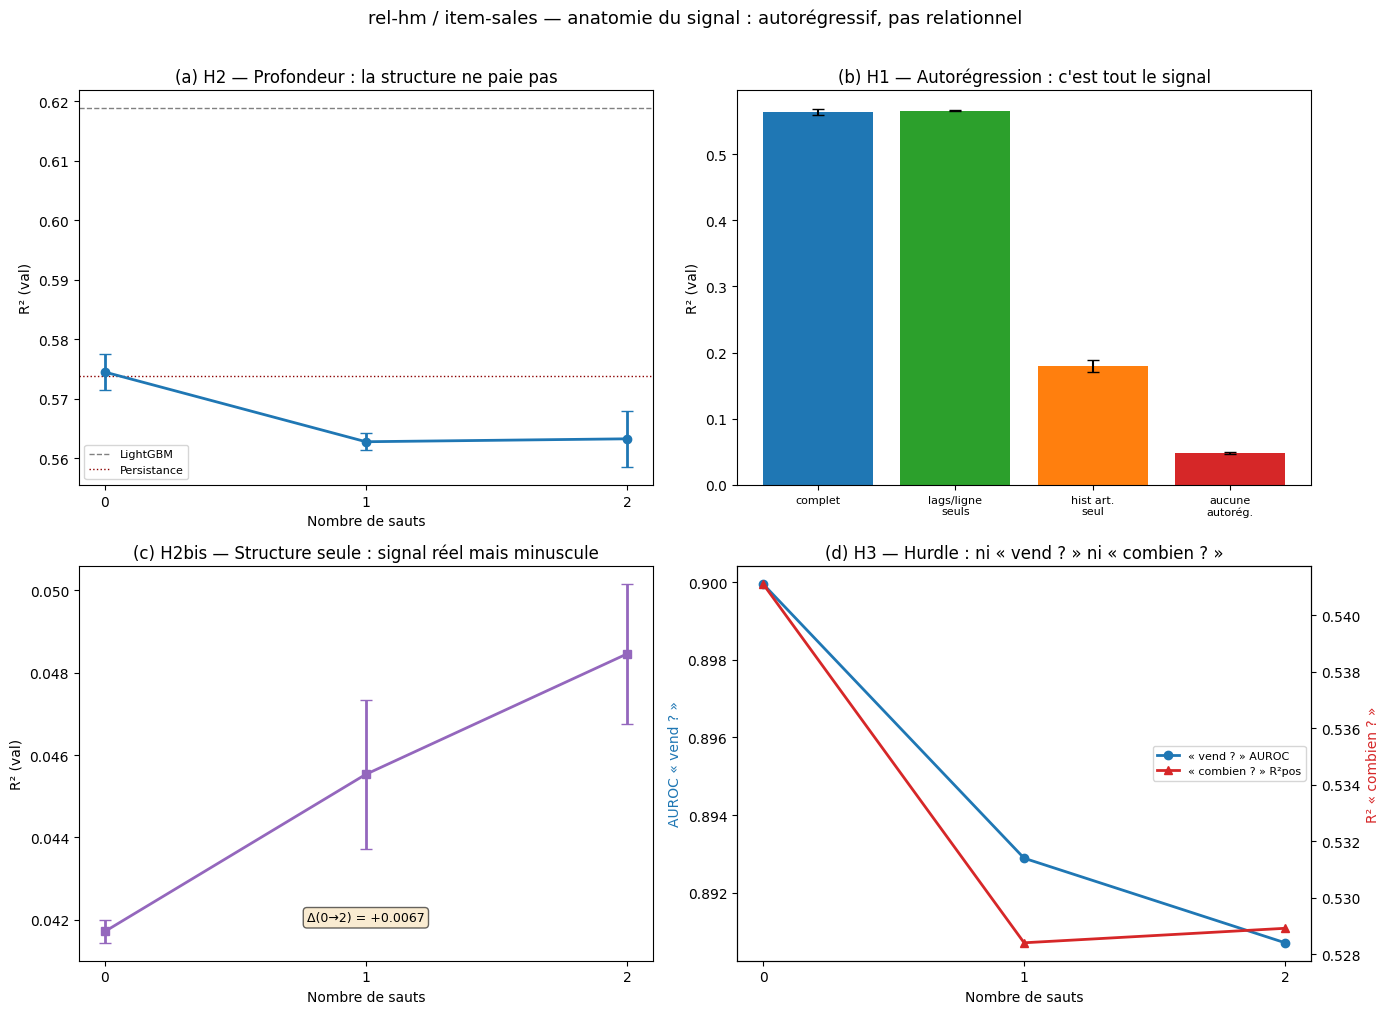

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (a) H2 — profondeur
m, sd = agg_depth[('r2','mean')], agg_depth[('r2','std')]
ax[0,0].errorbar(m.index, m.values, yerr=sd.values, marker='o', capsize=4, lw=2, color='C0')
ax[0,0].axhline(REF['LightGBM']['r2'],        ls='--', color='gray',    lw=1, label='LightGBM')
ax[0,0].axhline(REF['Persistance (lag1)']['r2'], ls=':', color='darkred', lw=1, label='Persistance')
ax[0,0].set_title('(a) H2 — Profondeur : la structure ne paie pas')
ax[0,0].set_xlabel('Nombre de sauts'); ax[0,0].set_ylabel('R² (val)')
ax[0,0].set_xticks([0,1,2]); ax[0,0].legend(fontsize=8)

# (b) H1 — autorégression
gt = temporal_s.groupby(['use_temporal','use_art_hist'])['r2'].agg(['mean','std'])
order_b = [(True,True),(True,False),(False,True),(False,False)]
labels_b = ['complet','lags/ligne\nseuls','hist art.\nseul','aucune\nautorég.']
xs = range(4)
ax[0,1].bar(xs, [gt.loc[o,'mean'] for o in order_b],
            yerr=[gt.loc[o,'std'] for o in order_b],
            capsize=4, color=['C0','C2','C1','C3'])
ax[0,1].set_xticks(list(xs)); ax[0,1].set_xticklabels(labels_b, fontsize=8)
ax[0,1].set_title("(b) H1 — Autorégression : c'est tout le signal")
ax[0,1].set_ylabel('R² (val)')

# (c) H2bis — structure seule
gs = struct_s.groupby('n_layers')['r2'].agg(['mean','std'])
ax[1,0].errorbar(gs.index, gs['mean'], yerr=gs['std'], marker='s', capsize=4, lw=2, color='C4')
ax[1,0].set_title('(c) H2bis — Structure seule : signal réel mais minuscule')
ax[1,0].set_xlabel('Nombre de sauts'); ax[1,0].set_ylabel('R² (val)')
ax[1,0].set_xticks([0,1,2])
ax[1,0].annotate(f"Δ(0→2) = {gs['mean'][2]-gs['mean'][0]:+.4f}",
                 xy=(0.5,0.1), xycoords='axes fraction', ha='center', fontsize=9,
                 bbox=dict(boxstyle='round', fc='wheat', alpha=0.6))

# (d) H3 — hurdle
ax2 = ax[1,1].twinx()
ax[1,1].plot(agg_hurdle.index, agg_hurdle['auroc'],  marker='o', color='C0', lw=2, label='« vend ? » AUROC')
ax2.plot(    agg_hurdle.index, agg_hurdle['r2_pos'], marker='^', color='C3', lw=2, label='« combien ? » R²pos')
ax[1,1].set_title('(d) H3 — Hurdle : ni « vend ? » ni « combien ? »')
ax[1,1].set_xlabel('Nombre de sauts'); ax[1,1].set_xticks([0,1,2])
ax[1,1].set_ylabel('AUROC « vend ? »', color='C0')
ax2.set_ylabel('R² « combien ? »', color='C3')
lines = ax[1,1].get_lines() + ax2.get_lines()
ax[1,1].legend(lines, [l.get_label() for l in lines], fontsize=8, loc='center right')

fig.suptitle('rel-hm / item-sales — anatomie du signal : autorégressif, pas relationnel',
             fontsize=13, y=1.01)
plt.tight_layout()
FIGS = Path('reports/figures'); FIGS.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGS/'hm_ablation_synthesis.png', dpi=130, bbox_inches='tight')
print(f'Figure sauvegardée dans reports/figures/hm_ablation_synthesis.png')
plt.show()

## Thèse — `rel-hm / item-sales`

Quand la cible est une série temporelle de comptage fortement autocorrélée, le signal
prédictif est autorégressif, pas relationnel.

À modèle GNN fixe, en ne faisant varier que la quantité de structure visible (3 seeds, val officiel) :

1. L'autorégression est tout le signal (H1). Δ R² ≈ +0.51 entre le modèle complet et le modèle
   privé de toute autorégression. La forme compte : des lags bruts par ligne (R² 0.57) écrasent
   l'historique agrégé (R² 0.18) ; il faut un chemin linéaire direct vers la tête, exactement ce
   qui fait gagner LightGBM.

2. La structure de co-achat porte un signal réel mais minuscule (H2bis). Sans autorégression, R²
   monte de façon monotone de 0 à 1 à 2 sauts, mais Δ ≈ +0.007 seulement, soit ~70× moins que
   l'autorégression.

3. En présence de l'autorégression, la structure devient nuisible (H2). Δ R² ≈ −0.011 de 0 à 2
   sauts : l'agrégation `mean` lisse le `lag1` brut qui porte le signal.

4. Le verrou est la magnitude, pas la détection (H3, hurdle). Le « vend ? » est quasi résolu dès
   0 saut (AUROC ≈ 0.90) ; le point dur est le « combien ? » (99.5 % de la masse d'erreur), et la
   structure n'y aide pas (Δ R²pos ≈ −0.012).

5. Ce n'est pas un artefact de sparsification (H2ter). Tripler les arêtes (K de 30 à 100, 1.3 M à
   3.2 M) ne change rien au signe.

6. Ni un artefact de l'agrégateur (H2quater). `sum` et `max`, qui préservent la magnitude, ne
   renversent rien avec autorégression (le meilleur reste sous le 0 saut).

Les expériences complémentaires (hop decay, feature ablation, rich features) confirment que les
catégorielles article sont du bruit pour le GNN (+0.007 R² en les supprimant), que les features
comportementales client n'apportent rien de plus, et que le discount du 2e hop reste dans le bruit.

En pratique, le meilleur GNN ici est le moins profond (0 saut) : une table plate neuronale, plus
simple et plus rapide, au niveau de la persistance. Le coût du message passing n'est pas justifié
sur cette cible.

### Mise en perspective
Sur une tâche où l'état de l'entité n'est lisible que via ses voisins, la même méthode d'ablation
montre l'inverse : un seul saut apporte l'essentiel. Le constat n'est donc pas que « les GNN ne
servent à rien », mais que l'apport relationnel dépend du défi de la base. Ici, l'autocorrélation
de l'entité plafonne ce que la structure peut ajouter.

### Limites
- Une seule relation (co-achat) et une seule tâche/cible ; conclusion propre aux cibles autocorrélées.
- Agrégateurs testés : mean / sum / max. GAT non testé (il normalise aussi, peu d'espoir).
- Densité testée jusqu'à K=100 ; au-delà, le full-batch sature le P100 (pas de sampling PyG).